# Sistema de recomendación personalizada de recursos y rutas de aprendizaje

Este notebook documenta la implementación del componente inteligente. Se integran cuatro módulos, todos de ejecución local (**no requiere clave de API**):

| # | Módulo | Técnica | Biblioteca |
|---|---|---|---|
| 1 | Clasificación del tipo de apoyo (*Refuerzo* o *Avanzado*) | Árbol de decisión | scikit-learn |
| 2 | Ruta de aprendizaje hacia una meta | Grafo de conocimiento + búsqueda **A\*** | networkx / heapq |
| 3 | Decisiones de excepción | Reglas de producción SI-ENTONCES | Python |
| 4 | Ordenamiento de recursos | Filtrado basado en contenido | Python |

> **Datos:** telemetría **simulada**; no corresponde a registros reales de estudiantes.

**Ejecución.** *Local:* `pip install -r requirements.txt` y abrir este notebook. *Google Colab:* cargar `recomendador.py`, `telemetria_estudiantes_simulada.csv` y `grafo_conocimiento.json` en el panel de archivos y ejecutar las celdas en orden.

In [1]:
# Instalación de gradio cuando no está disponible en el entorno
import importlib.util, subprocess, sys
if importlib.util.find_spec("gradio") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gradio"])

import pandas as pd, matplotlib.pyplot as plt
import recomendador as R
pd.set_option("display.width", 160)

## 1. Entradas: datos y conocimiento
Se utilizan dos fuentes: la telemetría simulada (CSV, generado con `generar_datos.py`) y el grafo de conocimiento con prerrequisitos y recursos (JSON).

In [2]:
rec = R.Recomendador("telemetria_estudiantes_simulada.csv", "grafo_conocimiento.json")
df = rec.df
print("Registros:", len(df), "| Temas en el grafo:", len(rec.grafo))
print("\nValores nulos por columna:"); print(df.isna().sum()[df.isna().sum() > 0])
df.head(8)

Registros: 100 | Temas en el grafo: 5

Valores nulos por columna:
Tiempo_Interaccion_Segundos    5
dtype: int64


,ID_Estudiante,Nivel_Previo,Formato_Preferido,Tema_Actual,Tiempo_Interaccion_Segundos,Tasa_Errores,Recurso_Recomendado_ID,Tipo_Apoyo
0,1,Avanzado,Práctico,Backend con Node.js,224.0,32.70,Avanzado_Práctico_BACK,Avanzado
1,2,Intermedio,Práctico,Patrón MVC en PHP,236.0,44.41,Avanzado_Texto_PATR,Avanzado
2,3,Avanzado,Visual,Bases de Datos PostgreSQL,168.0,33.70,Avanzado_Visual_BASE,Avanzado
3,4,Avanzado,Práctico,Lógica de Programación,42.0,43.81,Avanzado_Práctico_LÓGI,Avanzado
4,5,Principiante,Práctico,Lógica de Programación,123.0,91.79,Refuerzo_Práctico_LÓGI,Refuerzo
5,6,Avanzado,Práctico,Lógica de Programación,299.0,0.50,Avanzado_Práctico_LÓGI,Avanzado
6,7,Avanzado,Texto,Lógica de Programación,22.0,34.08,Avanzado_Texto_LÓGI,Avanzado
7,8,Avanzado,Visual,Backend con Node.js,264.0,44.41,Avanzado_Visual_BACK,Avanzado


In [3]:
print("Distribución del tipo de apoyo (variable que predice el árbol):")
print(df["Tipo_Apoyo"].value_counts())
print("\nTasa de errores por tipo de apoyo:")
df.groupby("Tipo_Apoyo")["Tasa_Errores"].describe().round(1)

Distribución del tipo de apoyo (variable que predice el árbol):
Tipo_Apoyo
Avanzado    56
Refuerzo    44
Name: count, dtype: int64

Tasa de errores por tipo de apoyo:


,count,mean,std,min,25%,50%,75%,max
Tipo_Apoyo,,,,,,,,
Avanzado,56.0,33.1,19.0,0.5,19.0,33.6,45.4,83.6
Refuerzo,44.0,72.1,13.6,46.8,62.7,70.0,81.0,99.5


## 2. Preprocesamiento
La función `construir_preprocesador()` aplica la **mediana** a los tiempos nulos (~5 %), codificación **ordinal** al nivel (Principiante < Intermedio < Avanzado) y codificación **one-hot** al formato y al tema (variables nominales). Forma parte del mismo *pipeline* que el modelo, por lo que el tratamiento es idéntico para los datos nuevos que ingresan desde la interfaz.

In [4]:
prep = R.construir_preprocesador().fit(df[R.COLUMNAS_X])
X_prep = pd.DataFrame(prep.transform(df[R.COLUMNAS_X]), columns=prep.get_feature_names_out())
print("Antes :", df[R.COLUMNAS_X].shape, " Después:", X_prep.shape)
X_prep.head(5).round(2)

Antes : (100, 5)  Después: (100, 11)


,tiempo__Tiempo_Interaccion_Segundos,errores__Tasa_Errores,nivel__Nivel_Previo,cat__Formato_Preferido_Visual,cat__Formato_Preferido_Texto,cat__Formato_Preferido_Práctico,cat__Tema_Actual_Lógica de Programación,cat__Tema_Actual_Programación Orientada a Objetos,cat__Tema_Actual_Bases de Datos PostgreSQL,cat__Tema_Actual_Backend con Node.js,cat__Tema_Actual_Patrón MVC en PHP
0,224.0,32.70,2.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,236.0,44.41,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,168.0,33.70,2.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,42.0,43.81,2.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
4,123.0,91.79,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0


## 3. Componente de IA #1: árbol de decisión
El árbol se entrena con el 80 % de los datos y se evalúa con el 20 % restante (partición estratificada). El modelo predice el **tipo de apoyo**; el formato y el tema del recurso se determinan a partir del perfil del estudiante y del grafo de conocimiento.

In [5]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import cross_val_score
from sklearn.tree import export_text, plot_tree

X_tr, X_te, y_tr, y_te = rec.particion
pred = rec.modelo_eval.predict(X_te)
print(f"Exactitud en prueba (20 %): {accuracy_score(y_te, pred):.2%}")
cv = cross_val_score(R.construir_modelo(), df[R.COLUMNAS_X], df["Tipo_Apoyo"], cv=5)
print("Validación cruzada (5 pliegues):", cv.round(2), "| media:", f"{cv.mean():.2%}")
print()
print(classification_report(y_te, pred))

arbol = rec.modelo.named_steps["arbol"]
nombres = list(rec.modelo.named_steps["prep"].get_feature_names_out())
print("Reglas aprendidas por el árbol (caja blanca):")
print(export_text(arbol, feature_names=nombres))

Exactitud en prueba (20 %): 90.00%
Validación cruzada (5 pliegues): [0.85 0.9  0.9  0.95 0.85] | media: 89.00%

              precision    recall  f1-score   support

    Avanzado       0.85      1.00      0.92        11
    Refuerzo       1.00      0.78      0.88         9

    accuracy                           0.90        20
   macro avg       0.92      0.89      0.90        20
weighted avg       0.92      0.90      0.90        20

Reglas aprendidas por el árbol (caja blanca):
|--- errores__Tasa_Errores <= 53.43
|   |--- errores__Tasa_Errores <= 46.13
|   |   |--- class: Avanzado
|   |--- errores__Tasa_Errores >  46.13
|   |   |--- nivel__Nivel_Previo <= 0.50
|   |   |   |--- cat__Formato_Preferido_Visual <= 0.50
|   |   |   |   |--- class: Refuerzo
|   |   |   |--- cat__Formato_Preferido_Visual >  0.50
|   |   |   |   |--- class: Avanzado
|   |   |--- nivel__Nivel_Previo >  0.50
|   |   |   |--- class: Avanzado
|--- errores__Tasa_Errores >  53.43
|   |--- nivel__Nivel_Previo <= 1.5

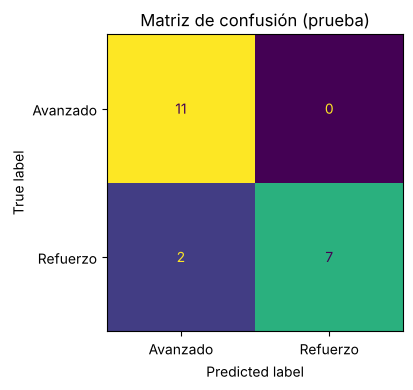

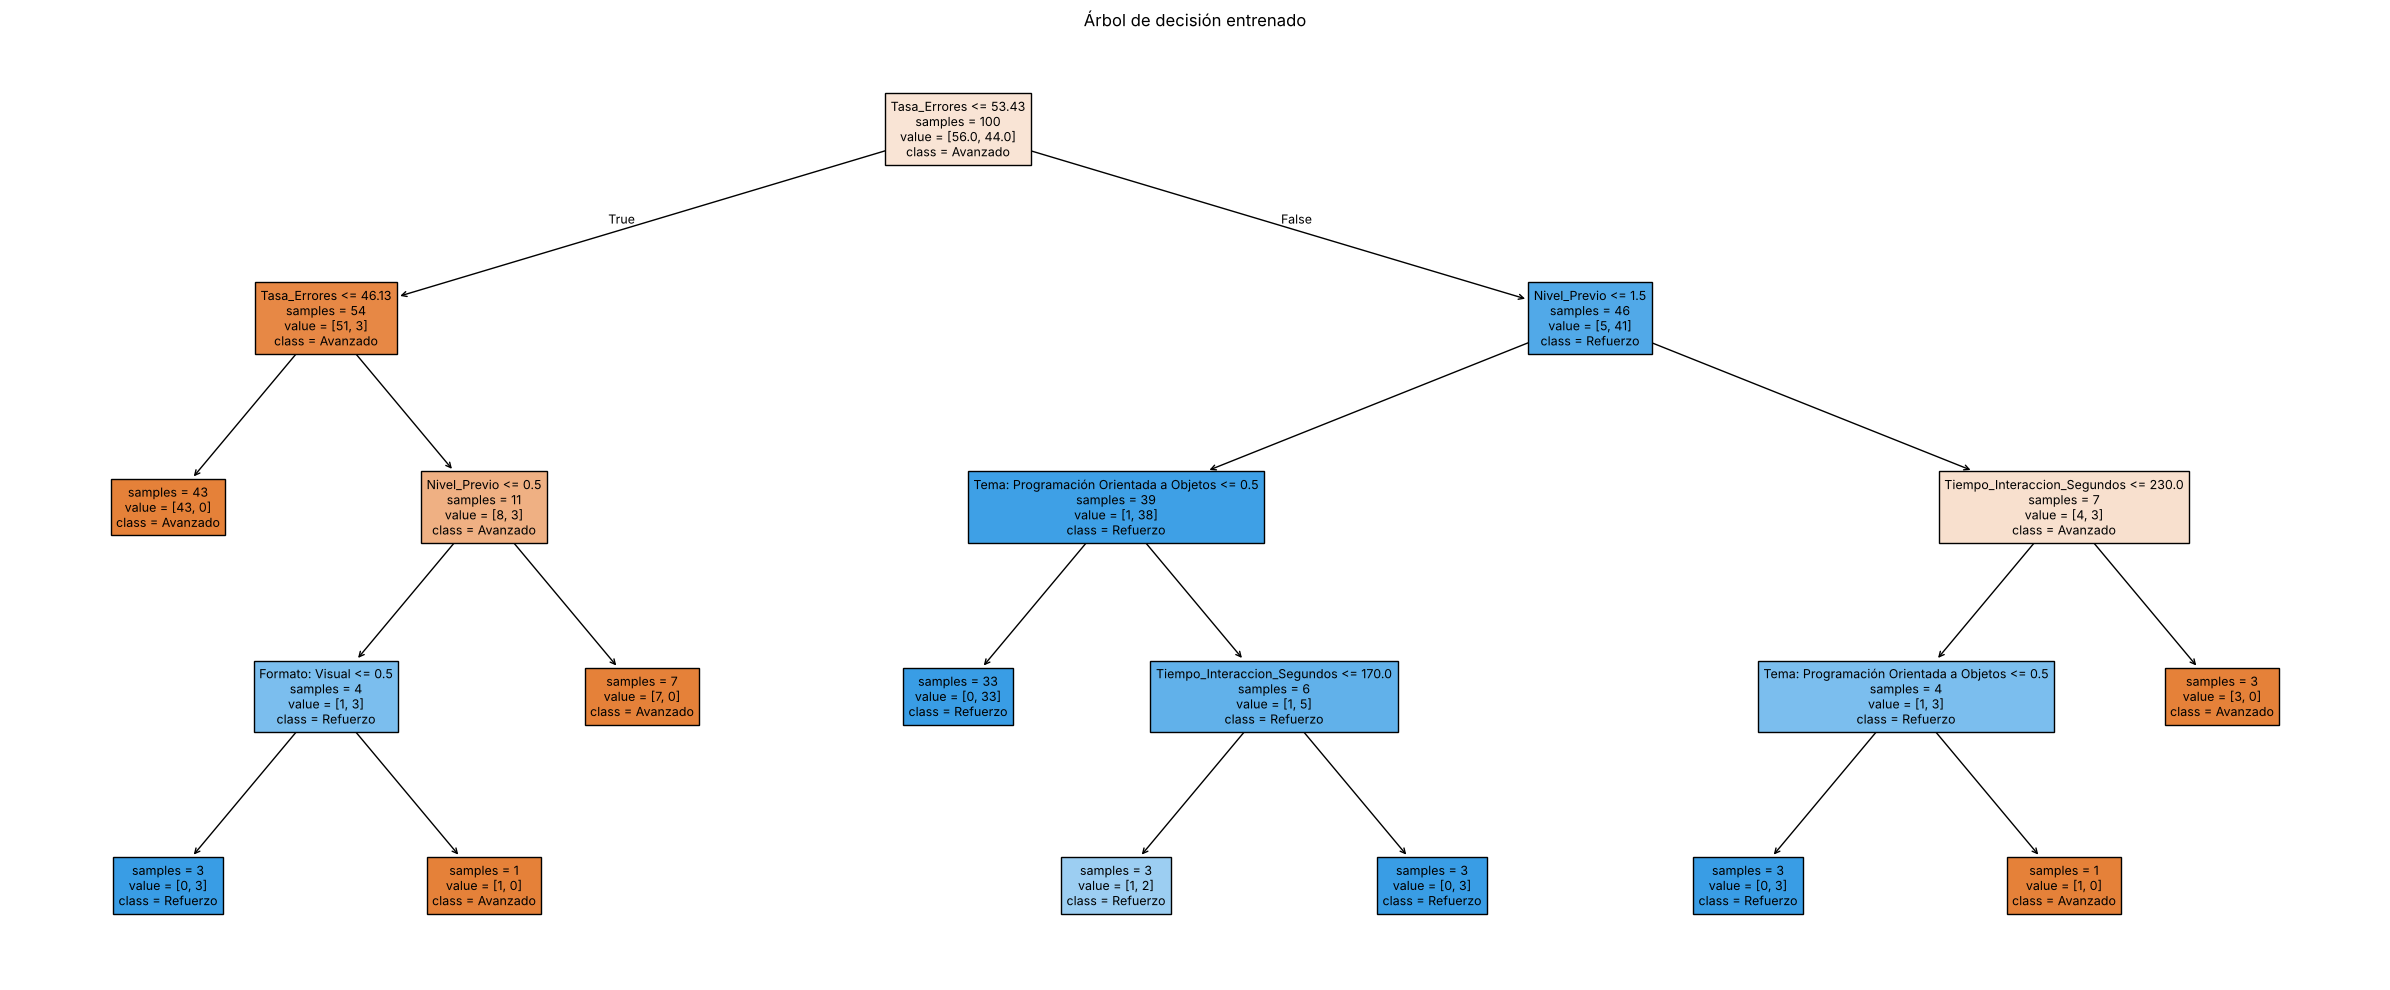

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=arbol.classes_), display_labels=arbol.classes_).plot(ax=ax, colorbar=False)
ax.set_title("Matriz de confusión (prueba)")
plt.tight_layout(); plt.show()

nombres_cortos = [n.split("__", 1)[1].replace("Tema_Actual_", "Tema: ").replace("Formato_Preferido_", "Formato: ") for n in nombres]
fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(arbol, feature_names=nombres_cortos, class_names=list(arbol.classes_), filled=True, impurity=False, ax=ax, fontsize=9)
ax.set_title("Árbol de decisión entrenado")
plt.tight_layout(); plt.show()

> **Interpretación del resultado.** El árbol alcanza una exactitud alta pero no perfecta: la etiqueta simulada se genera a partir de la tasa de errores, el nivel previo y el tiempo de interacción, con ruido aleatorio, por lo que los casos cercanos al umbral no son completamente separables. La tasa de errores es la variable dominante; el nivel y el tiempo actúan como criterios secundarios. Las divisiones adicionales sobre el formato o el tema reflejan sobreajuste al ruido con un número reducido de registros. Dado que los datos se generan con una función conocida, la exactitud mide la capacidad del modelo para recuperar esa relación y **no permite inferir** su desempeño con estudiantes reales, para lo cual se requiere una evaluación posterior con datos reales.

### 3.1 Comparación con un modelo de línea base
Como referencia, se entrena un árbol directamente sobre el identificador completo del recurso (`Recurso_Recomendado_ID`; 29 clases con solo 100 registros), con codificación ordinal de las variables categóricas.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

d2 = pd.read_csv("telemetria_estudiantes_simulada.csv")
d2["Tiempo_Interaccion_Segundos"] = SimpleImputer(strategy="median").fit_transform(d2[["Tiempo_Interaccion_Segundos"]])
le = LabelEncoder()
for c in ["Nivel_Previo", "Formato_Preferido", "Tema_Actual"]:
    d2[c + "_Cod"] = le.fit_transform(d2[c])
X2 = d2[["Nivel_Previo_Cod", "Formato_Preferido_Cod", "Tema_Actual_Cod", "Tiempo_Interaccion_Segundos", "Tasa_Errores"]]
a, b, c_, d_ = train_test_split(X2, d2["Recurso_Recomendado_ID"], test_size=0.2, random_state=42)
base = DecisionTreeClassifier(max_depth=5, random_state=42).fit(a, c_)
print(f"Modelo base (29 clases)      : exactitud = {base.score(b, d_):.2%}  | clases distintas = {d2['Recurso_Recomendado_ID'].nunique()}")
print(f"Modelo propuesto (2 clases)  : exactitud = {accuracy_score(y_te, pred):.2%}")
print("Clases de prueba que el modelo base nunca vio al entrenar:", set(d_) - set(c_))

Modelo base (29 clases)      : exactitud = 55.00%  | clases distintas = 29
Modelo propuesto (2 clases)  : exactitud = 90.00%
Clases de prueba que el modelo base nunca vio al entrenar: {'Avanzado_Texto_BASE', 'Refuerzo_Texto_PROG'}


## 4. Componente de IA #2: grafo de conocimiento y búsqueda A*
El grafo (JSON) define 5 temas y sus prerrequisitos. La función `ruta_a_estrella()` determina la secuencia de menor costo hacia una meta a partir de los temas ya completados. El costo de cada tema es `dificultad × factor del nivel` (parámetros fijados manualmente en `recomendador.py`).

In [8]:
print("Prerrequisitos del grafo:")
for p, t in rec.aristas:
    print(f"  {R.NODO_A_TEMA[p]}  →  {R.NODO_A_TEMA[t]}")

for nivel in R.NIVELES:
    ruta, costo, expl = R.ruta_a_estrella(rec.grafo, set(), "Backend_con_Nodejs", nivel)
    print(f"\n{nivel:12s} | costo = {costo:5.1f} | estados explorados = {expl}")
    print("   ", " → ".join(R.NODO_A_TEMA[n] for n in ruta))

Prerrequisitos del grafo:
  Lógica de Programación  →  Programación Orientada a Objetos
  Lógica de Programación  →  Bases de Datos PostgreSQL
  Programación Orientada a Objetos  →  Backend con Node.js
  Bases de Datos PostgreSQL  →  Backend con Node.js
  Programación Orientada a Objetos  →  Patrón MVC en PHP

Principiante | costo =  18.0 | estados explorados = 6
    Lógica de Programación → Programación Orientada a Objetos → Bases de Datos PostgreSQL → Backend con Node.js

Intermedio   | costo =  12.0 | estados explorados = 6
    Lógica de Programación → Programación Orientada a Objetos → Bases de Datos PostgreSQL → Backend con Node.js

Avanzado     | costo =   8.4 | estados explorados = 6
    Lógica de Programación → Programación Orientada a Objetos → Bases de Datos PostgreSQL → Backend con Node.js


## 5. Ejemplos de entrada y resultados
Se presentan cuatro casos que ejercitan cada módulo del sistema. Cada resultado indica la acción, el tema, los recursos ordenados del tema actual, la **ruta completa hacia la meta con un recurso por cada paso** y la justificación de la recomendación. La ruta es la secuencia de temas calculada por A*; los recursos de cada paso se obtienen del filtrado por contenido según el formato preferido.

In [9]:
casos = {
 "Caso 1 · Principiante visual con muchos errores (sin reglas de excepción)":
   dict(nivel="Principiante", formato="Visual", tema="Lógica de Programación", tiempo=120, errores=75,
        completados=[], meta="Backend con Node.js"),
 "Caso 2 · Tema bloqueado por prerrequisitos (regla R1)":
   dict(nivel="Avanzado", formato="Práctico", tema="Backend con Node.js", tiempo=100, errores=30,
        completados=["Lógica de Programación"], meta="Backend con Node.js"),
 "Caso 3 · Abandono con poco tiempo (regla R3, evita lecturas)":
   dict(nivel="Intermedio", formato="Texto", tema="Programación Orientada a Objetos", tiempo=20, errores=45,
        completados=["Lógica de Programación"], meta="Backend con Node.js", abandono=True),
 "Caso 4 · Fallos repetidos (regla R2, retroceso al prerrequisito)":
   dict(nivel="Principiante", formato="Práctico", tema="Patrón MVC en PHP", tiempo=150, errores=50,
        completados=["Lógica de Programación", "Programación Orientada a Objetos"],
        meta="Patrón MVC en PHP", fallos=3),
}
from IPython.display import Markdown, display
resultados = {}
for titulo, kw in casos.items():
    r = rec.recomendar(**kw); resultados[titulo] = r
    display(Markdown(f"---\n## {titulo}\n**Entrada:** `{kw}`\n\n" + R.formatear(r)))

---
## Caso 1 · Principiante visual con muchos errores (sin reglas de excepción)
**Entrada:** `{'nivel': 'Principiante', 'formato': 'Visual', 'tema': 'Lógica de Programación', 'tiempo': 120, 'errores': 75, 'completados': [], 'meta': 'Backend con Node.js'}`

### Acción sugerida: **Reforzar**
**Tema recomendado:** Lógica de Programación  
**Clasificación del árbol de decisión:** Refuerzo · confianza 100%

#### Recursos recomendados
1. `Recurso_Video_Logica` — Visual (puntaje 1.0) · Principal (coincide con su formato preferido)
2. `Recurso_Practica_Logica` — Práctico (puntaje 0.6) · Alternativa (diversificación contra burbuja de filtro)
3. `Recurso_Lectura_Logica` — Texto (puntaje 0.5) · Alternativa (diversificación contra burbuja de filtro)

#### Ruta de aprendizaje hacia la meta, con recurso por paso (A*)
| Paso | Tema | Recurso principal | Formato |
|---|---|---|---|
| 1 | Lógica de Programación | `Recurso_Video_Logica` | Visual |
| 2 | Programación Orientada a Objetos | `Recurso_Video_POO` | Visual |
| 3 | Bases de Datos PostgreSQL | `Recurso_Video_DB` | Visual |
| 4 | Backend con Node.js | `Recurso_Video_Node` | Visual |

_Costo de la ruta: 18.0 · estados explorados: 6_

#### Reglas activadas
- Ninguna regla de excepción se activó; se usó solo la clasificación del árbol.

#### ¿Por qué esta recomendación?
- El árbol de decisión clasificó el caso como «Refuerzo» (confianza 100%) con tasa de errores 75 %.

> Sugerencia adaptativa: el docente puede revisarla o modificarla. No constituye una calificación ni diagnóstico definitivo.

---
## Caso 2 · Tema bloqueado por prerrequisitos (regla R1)
**Entrada:** `{'nivel': 'Avanzado', 'formato': 'Práctico', 'tema': 'Backend con Node.js', 'tiempo': 100, 'errores': 30, 'completados': ['Lógica de Programación'], 'meta': 'Backend con Node.js'}`

### Acción sugerida: **Avanzar**
**Tema recomendado:** Programación Orientada a Objetos  
**Clasificación del árbol de decisión:** Avanzado · confianza 100%

#### Recursos recomendados
1. `Recurso_Practica_POO` — Práctico (puntaje 1.0) · Principal (coincide con su formato preferido)
2. `Recurso_Video_POO` — Visual (puntaje 0.6) · Alternativa (diversificación contra burbuja de filtro)
3. `Recurso_Lectura_POO` — Texto (puntaje 0.5) · Alternativa (diversificación contra burbuja de filtro)

#### Ruta de aprendizaje hacia la meta, con recurso por paso (A*)
| Paso | Tema | Recurso principal | Formato |
|---|---|---|---|
| 1 | Programación Orientada a Objetos | `Recurso_Practica_POO` | Práctico |
| 2 | Bases de Datos PostgreSQL | `Recurso_Practica_DB` | Práctico |
| 3 | Backend con Node.js | `Recurso_Practica_Node` | Práctico |

_Costo de la ruta: 7.0 · estados explorados: 5_

#### Reglas activadas
- R1: prerrequisitos pendientes → se redirige al primer tema desbloqueado de la ruta.

#### ¿Por qué esta recomendación?
- El árbol de decisión clasificó el caso como «Avanzado» (confianza 100%) con tasa de errores 30 %.
- «Backend con Node.js» está bloqueado: faltan Programación Orientada a Objetos, Bases de Datos PostgreSQL. Se recomienda empezar por «Programación Orientada a Objetos».

> Sugerencia adaptativa: el docente puede revisarla o modificarla. No constituye una calificación ni diagnóstico definitivo.

---
## Caso 3 · Abandono con poco tiempo (regla R3, evita lecturas)
**Entrada:** `{'nivel': 'Intermedio', 'formato': 'Texto', 'tema': 'Programación Orientada a Objetos', 'tiempo': 20, 'errores': 45, 'completados': ['Lógica de Programación'], 'meta': 'Backend con Node.js', 'abandono': True}`

### Acción sugerida: **Avanzar**
**Tema recomendado:** Programación Orientada a Objetos  
**Clasificación del árbol de decisión:** Avanzado · confianza 100%

#### Recursos recomendados
1. `Recurso_Video_POO` — Visual (puntaje 0.6) · Principal (sustituto: el tema no tiene recurso en formato Texto)
2. `Recurso_Lectura_POO` — Texto (puntaje 0.5) · Alternativa (diversificación contra burbuja de filtro)
3. `Recurso_Practica_POO` — Práctico (puntaje 0.5) · Alternativa (diversificación contra burbuja de filtro)

#### Ruta de aprendizaje hacia la meta, con recurso por paso (A*)
| Paso | Tema | Recurso principal | Formato |
|---|---|---|---|
| 1 | Programación Orientada a Objetos | `Recurso_Video_POO` | Visual |
| 2 | Bases de Datos PostgreSQL | `Recurso_Video_DB` | Visual |
| 3 | Backend con Node.js | `Recurso_Video_Node` | Visual |

_Costo de la ruta: 10.0 · estados explorados: 5_

#### Reglas activadas
- R3: tiempo < 30 s y abandono → ajustar_perfil(Evita_Textos_Largos).

#### ¿Por qué esta recomendación?
- El árbol de decisión clasificó el caso como «Avanzado» (confianza 100%) con tasa de errores 45 %.
- Se detectó abandono con poco tiempo de interacción: se penalizan las lecturas largas.

> Sugerencia adaptativa: el docente puede revisarla o modificarla. No constituye una calificación ni diagnóstico definitivo.

---
## Caso 4 · Fallos repetidos (regla R2, retroceso al prerrequisito)
**Entrada:** `{'nivel': 'Principiante', 'formato': 'Práctico', 'tema': 'Patrón MVC en PHP', 'tiempo': 150, 'errores': 50, 'completados': ['Lógica de Programación', 'Programación Orientada a Objetos'], 'meta': 'Patrón MVC en PHP', 'fallos': 3}`

### Acción sugerida: **Retroceder**
**Tema recomendado:** Programación Orientada a Objetos  
**Clasificación del árbol de decisión:** Refuerzo · confianza 100%

#### Recursos recomendados
1. `Recurso_Practica_POO` — Práctico (puntaje 1.0) · Principal (coincide con su formato preferido)
2. `Recurso_Video_POO` — Visual (puntaje 0.6) · Alternativa (diversificación contra burbuja de filtro)
3. `Recurso_Lectura_POO` — Texto (puntaje 0.5) · Alternativa (diversificación contra burbuja de filtro)

#### Ruta de aprendizaje hacia la meta, con recurso por paso (A*)
| Paso | Tema | Recurso principal | Formato |
|---|---|---|---|
| 1 (Repaso) | Programación Orientada a Objetos | `Recurso_Practica_POO` | Práctico |
| 2 | Patrón MVC en PHP | `Recurso_Video_PHP` | Visual |

_Costo de la ruta: 4.5 · estados explorados: 2_

#### Reglas activadas
- R2: fallos repetidos (3 > 2) → recomendar_retroceso al prerrequisito.

#### ¿Por qué esta recomendación?
- El árbol de decisión clasificó el caso como «Refuerzo» (confianza 100%) con tasa de errores 50 %.
- Con 3 fallos seguidos se regresa a «Programación Orientada a Objetos» para cubrir brechas de conocimiento.

> Sugerencia adaptativa: el docente puede revisarla o modificarla. No constituye una calificación ni diagnóstico definitivo.

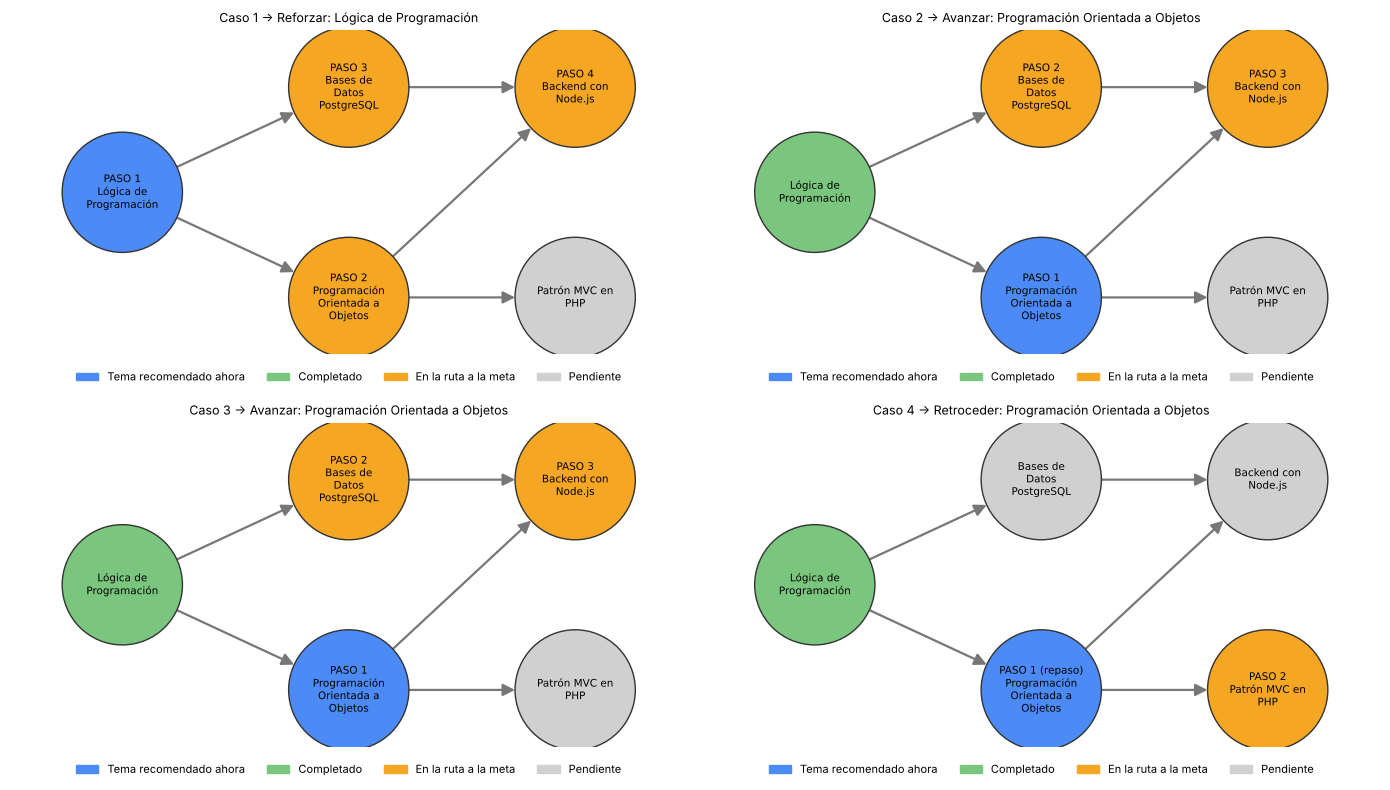

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (titulo, r) in zip(axes.ravel(), resultados.items()):
    R.dibujar_grafo(rec, r, ax=ax); ax.set_title(titulo.split("·")[0].strip() + f" → {r['accion']}: {r['tema_recomendado']}", fontsize=9)
plt.tight_layout(); plt.show()

## 6. Interfaz gráfica (Gradio)
Formulario para ingresar el perfil y la telemetría y visualizar la recomendación. Al ejecutar la celda en Colab o Jupyter, la interfaz se muestra debajo; en ejecución local también está disponible en `http://127.0.0.1:7860`.

In [11]:
demo = R.construir_interfaz(rec)
demo.launch()

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## 7. Ubicación de los componentes de IA
| Componente | Dónde se implementa | ¿Aprende de datos? |
|---|---|---|
| **Árbol de decisión** | `construir_modelo()` / `entrenar()`. Decide *Refuerzo* o *Avanzado* | Sí: aprende el umbral de errores |
| **Búsqueda A\*** | `ruta_a_estrella()`. Determina la ruta de menor costo en el grafo | No: razona sobre una estructura de conocimiento |
| **Reglas SI-ENTONCES** | `Recomendador.recomendar()`: R1 prerrequisitos, R2 fallos, R3 abandono | No: conocimiento codificado manualmente |
| **Filtrado por contenido** | `ordenar_recursos()`. Puntúa los recursos según el formato preferido | No: similitud simple |

**No constituyen componentes de IA:** la carga y limpieza de datos y la presentación de resultados.

## 8. Limitaciones conocidas
- Los datos son simulados y la etiqueta se genera a partir de una función conocida con ruido, por lo que la exactitud no constituye evidencia de desempeño real.
- Los costos de A* (dificultad y factor de nivel) son parámetros fijados manualmente, no valores medidos.
- Las variables `fallos consecutivos` y `abandono` no existen en el CSV; únicamente alimentan las reglas.
- Algunos temas no disponen de los tres formatos (p. ej., PostgreSQL no tiene lectura); en ese caso el sistema sustituye el formato e indica la sustitución.